# Galactic archaeology: single-target spectroscopy of halo and metal-poor stars

LFAST is **not** a multiplexed survey instrument (all telescopes point at one star), so its niche
in Galactic archaeology is depth on individual targets selected by Gaia, LAMOST, LSST or
Pristine-like photometry: extremely metal-poor candidates, stream members, hypervelocity stars,
and faint halo giants. At R ~ 1800 the metallicity precision is LAMOST-like (~0.1 dex at SNR
20-30 per pixel; Wu et al. 2014, Luo et al. 2015); the question is how faint and how fast.

**Assumptions** (knobs): SNR 30 per resel (~0.1 dex) in the 500-560 nm window; 2 min overhead per
target; G dwarf $M_V$ = +4.8, K giant $M_V$ = +0.5, red-giant-branch tip $M_V$ = -2.5 for the
distance reach; a 5800 K blackbody for dwarfs and 4500 K for giants; grey-time sky.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
# ---- knobs: array sizes compared throughout (replicated in arrays of 20) ----
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])
FIG = "../memo/figures/"      # memo figures are saved here as PDF
plt.rcParams.update({"font.size": 11, "axes.titlesize": 10, "legend.fontsize": 9})
def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)
def deq(n):
    return 0.726*np.sqrt(n)

In [3]:
WINDOW = (500, 560); SNR_FEH = 30; OVERHEAD = 120.0
dwarf = Source.blackbody(5800, 0, "V"); giant = Source.blackbody(4500, 0, "V")
def bench(n):
    return LFASTETC("bench_r1800", telescope=tel(n))

## Depth: limiting V for [Fe/H] in 15 min and 1 h

  900 s: N=20: V<16.9  N=200: V<18.8  N=1720: V<20.2
 3600 s: N=20: V<18.1  N=200: V<19.8  N=1720: V<21.1


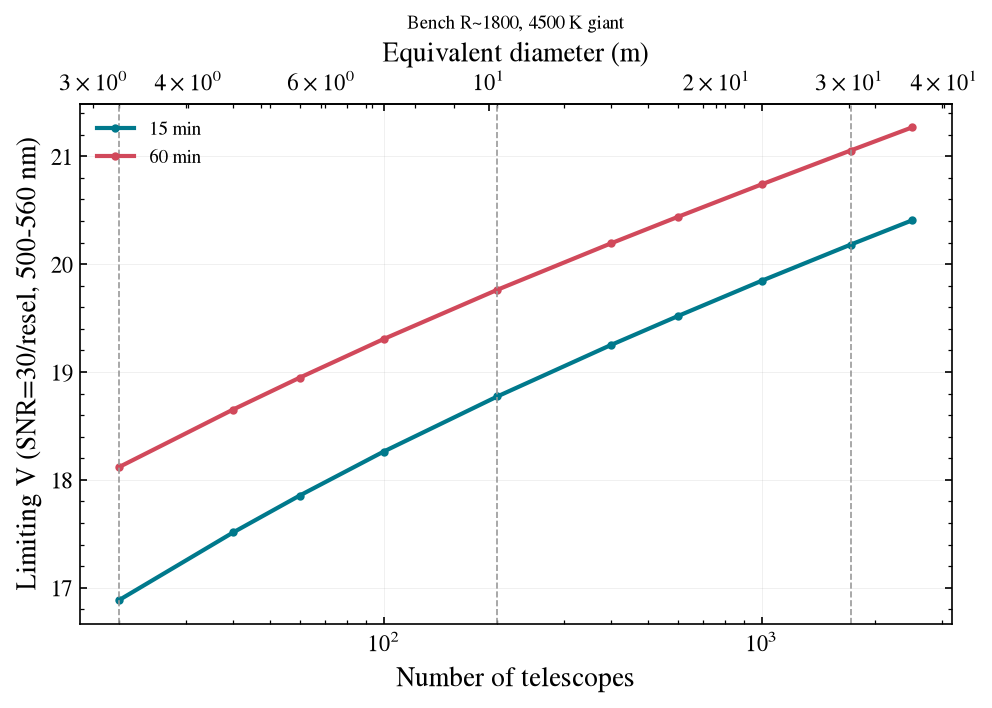

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
lims = {}
for exp, color in ((900, 'C0'), (3600, 'C1')):
    d = np.array([bench(int(n)).limiting_magnitude(giant, exp, SNR_FEH, wavelength=WINDOW) for n in NS])
    lims[exp] = dict(zip(NS, d))
    ax.plot(NS, d, marker='o', ms=3, color=color, label=f"{exp/60:.0f} min")
for n in (20, 200, 1720): ax.axvline(n, color='0.6', ls='--', lw=0.8)
ax.set_xscale('log'); ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting V (SNR=30/resel, 500-560 nm)")
ax.set_title("Bench R~1800, 4500 K giant", fontsize=9); ax.legend()
sec = ax.secondary_xaxis('top', functions=(deq, lambda d: (d/0.726)**2)); sec.set_xlabel("Equivalent diameter (m)")
fig.savefig(FIG + "metallicity_depth_vs_N.pdf")
for exp, d in lims.items():
    print(f"{exp:5d} s: " + "  ".join(f"N={n}: V<{d[n]:.1f}" for n in (20, 200, 1720)))

## Distance reach by tracer (1 h, SNR 30)

In [5]:
tracers = {"G dwarf (M_V=+4.8)": (dwarf, 4.8), "K giant (M_V=+0.5)": (giant, 0.5), "RGB tip (M_V=-2.5)": (giant, -2.5)}
print(f"{'tracer':22s}" + "".join(f"{'N=%d' % n:>14s}" for n in (20, 200, 1720)))
for label, (src, MV) in tracers.items():
    row = []
    for n in (20, 200, 1720):
        vlim = bench(n).limiting_magnitude(src, 3600, SNR_FEH, wavelength=WINDOW)
        d_kpc = 10**((vlim - MV + 5)/5)/1000
        row.append(f"{d_kpc:9.1f} kpc")
    print(f"{label:22s}" + "".join(f"{r:>14s}" for r in row))

tracer                          N=20         N=200        N=1720
G dwarf (M_V=+4.8)           4.7 kpc      10.1 kpc      18.2 kpc
K giant (M_V=+0.5)          33.4 kpc      71.2 kpc     129.0 kpc
RGB tip (M_V=-2.5)         133.0 kpc     283.4 kpc     513.7 kpc


## Survey speed: targets per 8 h night versus magnitude

N=   20: V=15:    110/night (  2.4 min each)  V=17:     25/night ( 16.9 min each)  V=19:      2/night (190.9 min each)
N=  200: V=15:    210/night (  0.3 min each)  V=17:    121/night (  2.0 min each)  V=19:     22/night ( 20.3 min each)
N= 1720: V=15:    233/night (  0.1 min each)  V=17:    201/night (  0.4 min each)  V=19:     93/night (  3.2 min each)


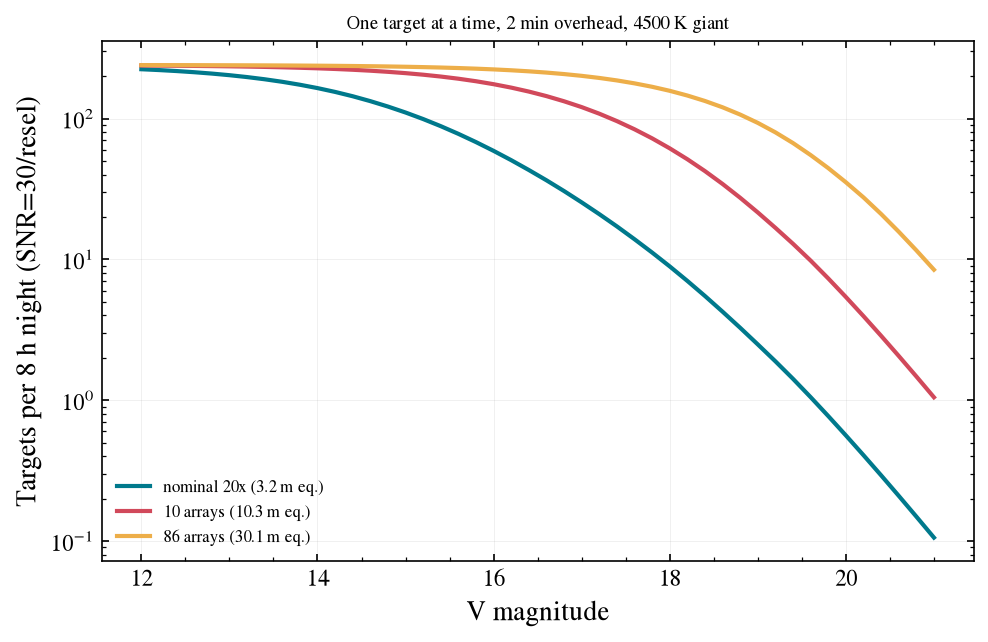

In [6]:
mags = np.linspace(12, 21, 46)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for n in (20, 200, 1720):
    t = bench(n).exptime_vs_mag(giant, mags, snr=SNR_FEH, wavelength=WINDOW)
    ax.plot(mags, 8*3600/(t + OVERHEAD), label=SCALES[n])
ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_ylabel("Targets per 8 h night (SNR=30/resel)")
ax.set_title("One target at a time, 2 min overhead, 4500 K giant", fontsize=9); ax.legend(fontsize=8)
fig.savefig(FIG + "survey_speed_vs_N.pdf")
for n in (20, 200, 1720):
    t = bench(n).exptime_vs_mag(giant, [15, 17, 19], snr=SNR_FEH, wavelength=WINDOW)
    print(f"N={n:5d}: " + "  ".join(f"V={m}: {8*3600/(ti+OVERHEAD):6.0f}/night ({ti/60:5.1f} min each)" for m, ti in zip((15, 17, 19), t)))

## Context: Gaia XP metal-poor candidates

Photometric metallicity catalogues from Gaia XP spectra contain ~10$^5$-10$^6$ candidates with
[Fe/H] < -2 at G ~ 13-17.5. At V ~ 16-17 the nominal array confirms a candidate in minutes, so the
20x array alone could verify thousands per season; the larger arrays push confirmation to the
faint, distant halo (V ~ 19-20) where multiplexed 4 m surveys run out of photons per fiber.

In [7]:
for n in (20, 200, 1720):
    t = bench(n).exptime_vs_mag(giant, [16, 17.5, 19, 20], snr=SNR_FEH, wavelength=WINDOW)
    print(f"N={n:5d}: " + "  ".join(f"V={m}: {ti/60:6.1f} min" for m, ti in zip((16, 17.5, 19, 20), t)))

N=   20: V=16:    6.1 min  V=17.5:   29.1 min  V=19:  190.9 min  V=20:  851.6 min
N=  200: V=16:    0.7 min  V=17.5:    3.3 min  V=19:   20.3 min  V=20:   86.8 min
N= 1720: V=16:    0.1 min  V=17.5:    0.6 min  V=19:    3.2 min  V=20:   11.6 min
